In [1]:
import fastf1
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("F1 Race Intelligence")
print("FastF1 version:", fastf1.__version__)
print("Pandas version:", pd.__version__)

F1 Race Intelligence
FastF1 version: 3.9.2
Pandas version: 2.3.3


In [1]:
import fastf1
import logging

fastf1.set_log_level("DEBUG")

session = fastf1.get_session(
    2024,
    "Italian Grand Prix",
    "R"
)

try:
    session.load(
        laps=True,
        telemetry=False,
        weather=False,
        messages=False
    )

    print("\nSession loading completed.")

    laps = session.laps.copy()
    print("Lap records:", len(laps))
    print("Drivers:", laps["Driver"].nunique())
    display(laps.head())

except Exception as e:
    print("\nLoading failed.")
    print("Error type:", type(e).__name__)
    print("Error message:", str(e))

req         WARNING 	DEFAULT CACHE ENABLED! (24.0 KB) C:\Users\HP\AppData\Local\Temp\fastf1
core           INFO 	Loading data for Italian Grand Prix - Race [v3.9.2]
req            INFO 	No cached data found for session_info. Loading data...
_api           INFO 	Fetching session info data...
tokens         INFO 	Signing in to Formula 1 account...
transport    WARNING 	Failed to authenticate with Formula 1 account, continuing without authentication: No F1 account credentials available. Set the environment variables F1_USERNAME and F1_PASSWORD.
req           DEBUG 	Falling back to https://livetiming-mirror.fastf1.dev/static/2024/2024-09-01_Italian_Grand_Prix/2024-09-01_Race/SessionInfo.jsonStream
logger      WARNING 	Failed to load session info data!
logger        DEBUG 	Traceback for failure in session info data
Traceback (most recent call last):
  File "d:\projects\f1-project\.venv\Lib\site-packages\fastf1\logger.py", line 112, in __wrapped
    return func(*args, **kwargs)
           ^^


Session loading completed.

Loading failed.
Error type: DataNotLoadedError
Error message: The data you are trying to access has not been loaded yet. See `Session.load`


In [2]:
import requests

url = (
    "https://livetiming.formula1.com/static/2024/"
    "2024-09-01_Italian_Grand_Prix/"
    "2024-09-01_Race/SessionInfo.jsonStream"
)

response = requests.get(
    url,
    headers={"User-Agent": "BestHTTP"},
    timeout=20
)

print("Status code:", response.status_code)
print("Response length:", len(response.content))
print("Response preview:", response.text[:200])

Status code: 401
Response length: 0
Response preview: 


In [3]:
import requests

url = "https://api.jolpi.ca/ergast/f1/2024/"

response = requests.get(url, timeout=20)

print("Status:", response.status_code)
print(response.text[:300])

Status: 200
{"MRData":{"xmlns":"","series":"f1","url":"https://api.jolpi.ca/ergast/f1/2024/","limit":"30","offset":"0","total":"24","RaceTable":{"season":"2024","Races":[{"season":"2024","round":"1","url":"https://en.wikipedia.org/wiki/2024_Bahrain_Grand_Prix","raceName":"Bahrain Grand Prix","Circuit":{"circuit


In [4]:
import requests

url = "https://api.jolpi.ca/ergast/f1/2024/"

response = requests.get(url, timeout=20)
data = response.json()

races = data["MRData"]["RaceTable"]["Races"]

for race in races:
    print(race["round"], race["raceName"], race["date"])

1 Bahrain Grand Prix 2024-03-02
2 Saudi Arabian Grand Prix 2024-03-09
3 Australian Grand Prix 2024-03-24
4 Japanese Grand Prix 2024-04-07
5 Chinese Grand Prix 2024-04-21
6 Miami Grand Prix 2024-05-05
7 Emilia Romagna Grand Prix 2024-05-19
8 Monaco Grand Prix 2024-05-26
9 Canadian Grand Prix 2024-06-09
10 Spanish Grand Prix 2024-06-23
11 Austrian Grand Prix 2024-06-30
12 British Grand Prix 2024-07-07
13 Hungarian Grand Prix 2024-07-21
14 Belgian Grand Prix 2024-07-28
15 Dutch Grand Prix 2024-08-25
16 Italian Grand Prix 2024-09-01
17 Azerbaijan Grand Prix 2024-09-15
18 Singapore Grand Prix 2024-09-22
19 United States Grand Prix 2024-10-20
20 Mexico City Grand Prix 2024-10-27
21 São Paulo Grand Prix 2024-11-03
22 Las Vegas Grand Prix 2024-11-23
23 Qatar Grand Prix 2024-12-01
24 Abu Dhabi Grand Prix 2024-12-08


In [5]:
import requests
import pandas as pd

url = "https://api.jolpi.ca/ergast/f1/2024/16/laps/?limit=1000"
response = requests.get(url, timeout=20)

print("Status:", response.status_code)

data = response.json()
laps_data = data["MRData"]["RaceTable"]["Races"][0]["Laps"]

rows = []

for lap in laps_data:
    for timing in lap["Timings"]:
        rows.append({
            "lap": int(lap["number"]),
            "driver": timing["driverId"],
            "position": int(timing["position"]),
            "time": timing["time"]
        })

laps_df = pd.DataFrame(rows)

laps_df.head()

Status: 200


,lap,driver,position,time
0,1,piastri,1,1:27.623
1,1,leclerc,2,1:28.179
2,1,norris,3,1:28.971
3,1,sainz,4,1:29.345
4,1,hamilton,5,1:29.674


In [6]:
print("Shape:", laps_df.shape)
print("\nColumns:")
print(laps_df.columns.tolist())

print("\nMissing values:")
print(laps_df.isnull().sum())

print("\nUnique drivers:", laps_df["driver"].nunique())
print("Laps covered:", laps_df["lap"].min(), "to", laps_df["lap"].max())

laps_df.head(10)

Shape: (100, 4)

Columns:
['lap', 'driver', 'position', 'time']

Missing values:
lap         0
driver      0
position    0
time        0
dtype: int64

Unique drivers: 20
Laps covered: 1 to 5


,lap,driver,position,time
0,1,piastri,1,1:27.623
1,1,leclerc,2,1:28.179
2,1,norris,3,1:28.971
3,1,sainz,4,1:29.345
4,1,hamilton,5,1:29.674
5,1,max_verstappen,6,1:30.354
6,1,russell,7,1:31.512
7,1,perez,8,1:31.698
8,1,albon,9,1:31.965
9,1,alonso,10,1:32.411


In [7]:
import requests
import pandas as pd

all_rows = []

for lap_number in range(1, 54):  # Monza 2024 had 53 race laps
    url = f"https://api.jolpi.ca/ergast/f1/2024/16/laps/{lap_number}/"
    response = requests.get(url, timeout=20)

    if response.status_code != 200:
        print("Stopped at lap:", lap_number, "Status:", response.status_code)
        break

    data = response.json()
    races = data["MRData"]["RaceTable"]["Races"]

    if not races or not races[0].get("Laps"):
        break

    for lap in races[0]["Laps"]:
        for timing in lap["Timings"]:
            all_rows.append({
                "lap": int(lap["number"]),
                "driver": timing["driverId"],
                "position": int(timing["position"]),
                "time": timing["time"]
            })

laps_df = pd.DataFrame(all_rows)

print("Shape:", laps_df.shape)
print("Lap range:", laps_df["lap"].min(), "to", laps_df["lap"].max())
print("Drivers:", laps_df["driver"].nunique())

laps_df.head()

Shape: (1008, 4)
Lap range: 1 to 53
Drivers: 20


,lap,driver,position,time
0,1,piastri,1,1:27.623
1,1,leclerc,2,1:28.179
2,1,norris,3,1:28.971
3,1,sainz,4,1:29.345
4,1,hamilton,5,1:29.674


In [8]:
def lap_time_to_seconds(time_str):
    minutes, seconds = time_str.split(":")
    return int(minutes) * 60 + float(seconds)

laps_df["lap_time_seconds"] = laps_df["time"].apply(lap_time_to_seconds)

laps_df.head()

,lap,driver,position,time,lap_time_seconds
0,1,piastri,1,1:27.623,87.623
1,1,leclerc,2,1:28.179,88.179
2,1,norris,3,1:28.971,88.971
3,1,sainz,4,1:29.345,89.345
4,1,hamilton,5,1:29.674,89.674


In [9]:
laps_df[["lap", "driver", "time", "lap_time_seconds"]].head(10)

,lap,driver,time,lap_time_seconds
0,1,piastri,1:27.623,87.623
1,1,leclerc,1:28.179,88.179
2,1,norris,1:28.971,88.971
3,1,sainz,1:29.345,89.345
4,1,hamilton,1:29.674,89.674
5,1,max_verstappen,1:30.354,90.354
6,1,russell,1:31.512,91.512
7,1,perez,1:31.698,91.698
8,1,albon,1:31.965,91.965
9,1,alonso,1:32.411,92.411


In [10]:
driver_pace = (
    laps_df.groupby("driver")["lap_time_seconds"]
    .agg(["mean", "median", "std", "count"])
    .sort_values("median")
)

driver_pace.head(10)

,mean,median,std,count
driver,,,,
norris,84.658113,83.652,4.155547,53
piastri,84.592283,83.660,4.130868,53
leclerc,84.542019,83.731,3.088701,53
max_verstappen,85.257717,83.801,4.478256,53
hamilton,84.972585,83.818,4.198589,53
sainz,84.836755,84.001,3.095268,53
russell,85.291358,84.546,5.194251,53
perez,85.563679,84.773,4.130441,53
kevin_magnussen,85.642057,84.803,3.417478,53


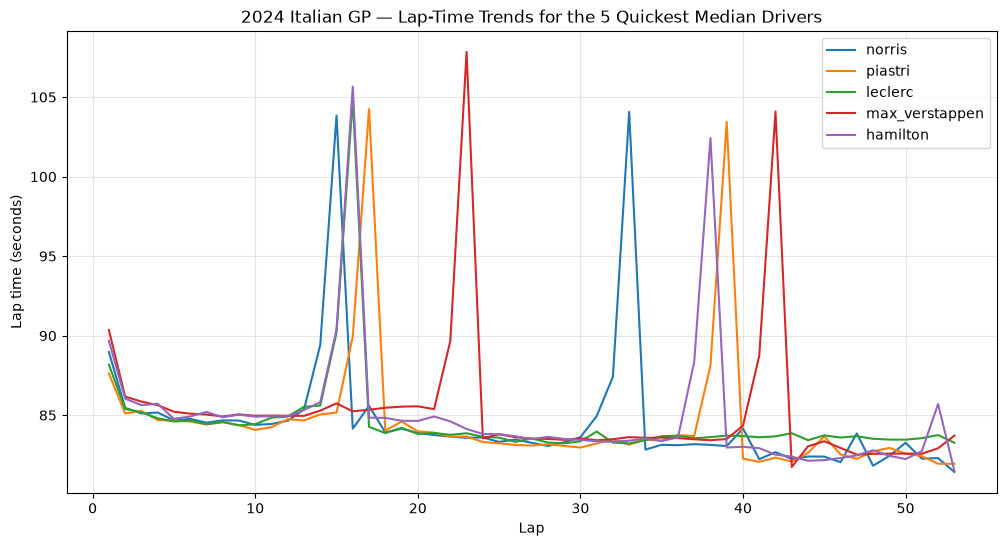

In [11]:
import matplotlib.pyplot as plt

top_drivers = driver_pace.head(5).index.tolist()

plt.figure(figsize=(12, 6))

for driver in top_drivers:
    driver_data = laps_df[laps_df["driver"] == driver]
    plt.plot(
        driver_data["lap"],
        driver_data["lap_time_seconds"],
        label=driver
    )

plt.xlabel("Lap")
plt.ylabel("Lap time (seconds)")
plt.title("2024 Italian GP — Lap-Time Trends for the 5 Quickest Median Drivers")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [12]:
slow_laps = laps_df[laps_df["lap_time_seconds"] > 100].sort_values(
    ["driver", "lap"]
)

print("Potential pit-stop / unusual laps:", len(slow_laps))
slow_laps[["lap", "driver", "position", "time", "lap_time_seconds"]]

Potential pit-stop / unusual laps: 31


,lap,driver,position,time,lap_time_seconds
342,18,albon,13,1:46.033,106.033
249,13,alonso,15,1:45.594,105.594
685,36,alonso,14,1:44.152,104.152
651,34,bottas,18,1:45.462,105.462
327,17,colapinto,17,1:46.349,106.349
214,11,gasly,18,1:45.677,105.677
595,31,gasly,19,1:45.757,105.757
301,16,hamilton,10,1:45.664,105.664
715,38,hamilton,6,1:42.426,102.426
119,6,hulkenberg,20,2:00.178,120.178


In [13]:
slow_laps.groupby("driver").size().sort_values(ascending=False)

driver
stroll             3
alonso             2
gasly              2
hulkenberg         2
piastri            2
russell            2
perez              2
hamilton           2
norris             2
max_verstappen     2
albon              1
bottas             1
colapinto          1
ocon               1
kevin_magnussen    1
leclerc            1
ricciardo          1
sainz              1
tsunoda            1
zhou               1
dtype: int64

In [14]:
url = "https://api.jolpi.ca/ergast/f1/2024/16/pitstops/?limit=100"
response = requests.get(url, timeout=20)

print("Status:", response.status_code)

pit_data = response.json()
race = pit_data["MRData"]["RaceTable"]["Races"][0]
pitstops = race["PitStops"]

pit_rows = []

for stop in pitstops:
    pit_rows.append({
        "driver": stop["driverId"],
        "lap": int(stop["lap"]),
        "stop_number": int(stop["stop"]),
        "duration": stop["duration"]
    })

pitstops_df = pd.DataFrame(pit_rows)

pitstops_df.sort_values(["driver", "lap"]).head(20)

Status: 200


,driver,lap,stop_number,duration
12,albon,17,1,24.801
4,alonso,12,1,24.866
24,alonso,35,2,24.501
22,bottas,33,1,24.410
11,colapinto,16,1,25.147
1,gasly,10,1,24.335
17,gasly,30,2,24.203
8,hamilton,15,1,24.469
26,hamilton,37,2,24.155
0,hulkenberg,5,1,38.875


In [15]:
# Create a set of (driver, lap) pairs where a pit stop was recorded
pit_lap_keys = set(
    zip(pitstops_df["driver"], pitstops_df["lap"])
)

laps_df["is_pit_lap"] = [
    (driver, lap) in pit_lap_keys
    for driver, lap in zip(laps_df["driver"], laps_df["lap"])
]

print("Recorded pit-stop laps matched:", laps_df["is_pit_lap"].sum())
laps_df[laps_df["is_pit_lap"]][
    ["lap", "driver", "position", "time", "lap_time_seconds"]
].head(15)

Recorded pit-stop laps matched: 30


,lap,driver,position,time,lap_time_seconds
97,5,hulkenberg,18,1:31.729,91.729
194,10,gasly,17,1:31.535,91.535
204,11,russell,8,1:31.175,91.175
210,11,ricciardo,14,1:31.962,91.962
226,12,alonso,11,1:29.740,89.740
257,14,norris,4,1:29.417,89.417
264,14,kevin_magnussen,11,1:29.943,89.943
275,15,leclerc,3,1:30.192,90.192
278,15,hamilton,6,1:30.365,90.365
285,15,zhou,13,1:32.048,92.048


In [16]:
clean_laps_df = laps_df[
    (~laps_df["is_pit_lap"]) &
    (laps_df["lap_time_seconds"] < 100)
].copy()

print("Original rows:", len(laps_df))
print("Clean rows:", len(clean_laps_df))
print("Drivers:", clean_laps_df["driver"].nunique())

clean_laps_df.head()

Original rows: 1008
Clean rows: 947
Drivers: 20


,lap,driver,position,time,lap_time_seconds,is_pit_lap
0,1,piastri,1,1:27.623,87.623,False
1,1,leclerc,2,1:28.179,88.179,False
2,1,norris,3,1:28.971,88.971,False
3,1,sainz,4,1:29.345,89.345,False
4,1,hamilton,5,1:29.674,89.674,False


In [17]:
import requests

BASE_URL = "https://api.jolpi.ca/ergast/f1"

season = 2024
round_num = 16

url = f"{BASE_URL}/{season}/{round_num}/laps/"

params = {
    "limit": 1000,
    "offset": 0
}

response = requests.get(url, params=params, timeout=30)

print("Status code:", response.status_code)
print("Request URL:", response.url)

response.raise_for_status()

data = response.json()

print("Top-level keys:", data.keys())
print("API metadata:", data.get("MRData", {}).get("total"))

Status code: 200
Request URL: https://api.jolpi.ca/ergast/f1/2024/16/laps/?limit=1000&offset=0
Top-level keys: dict_keys(['MRData'])
API metadata: 1008


In [18]:
race_table = data["MRData"]["RaceTable"]
races = race_table.get("Races", [])

print("Number of race entries:", len(races))

if races:
    laps = races[0].get("Laps", [])

    print("Number of lap groups returned:", len(laps))

    if laps:
        print("First lap record:")
        print(laps[0])

Number of race entries: 1
Number of lap groups returned: 5
First lap record:
{'number': '1', 'Timings': [{'driverId': 'piastri', 'time': '1:27.623', 'position': '1'}, {'driverId': 'leclerc', 'time': '1:28.179', 'position': '2'}, {'driverId': 'norris', 'time': '1:28.971', 'position': '3'}, {'driverId': 'sainz', 'time': '1:29.345', 'position': '4'}, {'driverId': 'hamilton', 'time': '1:29.674', 'position': '5'}, {'driverId': 'max_verstappen', 'time': '1:30.354', 'position': '6'}, {'driverId': 'russell', 'time': '1:31.512', 'position': '7'}, {'driverId': 'perez', 'time': '1:31.698', 'position': '8'}, {'driverId': 'albon', 'time': '1:31.965', 'position': '9'}, {'driverId': 'alonso', 'time': '1:32.411', 'position': '10'}, {'driverId': 'ricciardo', 'time': '1:33.104', 'position': '11'}, {'driverId': 'kevin_magnussen', 'time': '1:33.931', 'position': '12'}, {'driverId': 'gasly', 'time': '1:34.873', 'position': '13'}, {'driverId': 'tsunoda', 'time': '1:35.235', 'position': '14'}, {'driverId': '

In [19]:
mr_data = data["MRData"]

print("Total records:", mr_data.get("total"))
print("Limit:", mr_data.get("limit"))
print("Offset:", mr_data.get("offset"))

Total records: 1008
Limit: 100
Offset: 0


In [20]:
next_params = {
    "limit": 1000,
    "offset": 5
}

next_response = requests.get(url, params=next_params, timeout=30)

print("Status code:", next_response.status_code)

next_response.raise_for_status()

next_data = next_response.json()
next_mr = next_data["MRData"]

print("Total:", next_mr.get("total"))
print("Limit:", next_mr.get("limit"))
print("Offset:", next_mr.get("offset"))

next_races = next_mr["RaceTable"].get("Races", [])
next_laps = next_races[0].get("Laps", []) if next_races else []

print("Lap groups on next page:", len(next_laps))

if next_laps:
    print("First lap number on next page:", next_laps[0]["number"])

Status code: 200
Total: 1008
Limit: 100
Offset: 5
Lap groups on next page: 6
First lap number on next page: 1


In [21]:
for lap_group in laps:
    print(
        "Lap:", lap_group["number"],
        "| Driver timings:", len(lap_group["Timings"])
    )

Lap: 1 | Driver timings: 20
Lap: 2 | Driver timings: 20
Lap: 3 | Driver timings: 20
Lap: 4 | Driver timings: 20
Lap: 5 | Driver timings: 20


In [22]:
for lap_group in next_laps:
    print(
        "Lap:", lap_group["number"],
        "| Driver timings:", len(lap_group["Timings"])
    )

Lap: 1 | Driver timings: 15
Lap: 2 | Driver timings: 20
Lap: 3 | Driver timings: 20
Lap: 4 | Driver timings: 20
Lap: 5 | Driver timings: 20
Lap: 6 | Driver timings: 5


In [23]:
print("First request:")
print("Total:", data["MRData"]["total"])
print("Limit:", data["MRData"]["limit"])
print("Offset:", data["MRData"]["offset"])

print("\nSecond request:")
print("Total:", next_data["MRData"]["total"])
print("Limit:", next_data["MRData"]["limit"])
print("Offset:", next_data["MRData"]["offset"])

First request:
Total: 1008
Limit: 100
Offset: 0

Second request:
Total: 1008
Limit: 100
Offset: 5


In [24]:
params = {
    "limit": 100,
    "offset": 100
}

page_response = requests.get(url, params=params, timeout=30)

print("Status code:", page_response.status_code)
page_response.raise_for_status()

page_data = page_response.json()
page_mr = page_data["MRData"]

print("Total:", page_mr["total"])
print("Limit:", page_mr["limit"])
print("Offset:", page_mr["offset"])

page_races = page_mr["RaceTable"].get("Races", [])
page_laps = page_races[0].get("Laps", []) if page_races else []

print("Lap groups returned:", len(page_laps))

if page_laps:
    print("First lap number:", page_laps[0]["number"])
    print("Last lap number:", page_laps[-1]["number"])

Status code: 200
Total: 1008
Limit: 100
Offset: 100
Lap groups returned: 6
First lap number: 6
Last lap number: 11


In [25]:
import requests
import pandas as pd
import time

BASE_URL = "https://api.jolpi.ca/ergast/f1"

def fetch_race_laps(season, round_num, limit=100):
    url = f"{BASE_URL}/{season}/{round_num}/laps/"
    offset = 0
    total = None
    rows = []

    while total is None or offset < total:
        params = {"limit": limit, "offset": offset}
        response = requests.get(url, params=params, timeout=30)
        response.raise_for_status()

        mr_data = response.json()["MRData"]
        total = int(mr_data["total"])
        returned_limit = int(mr_data["limit"])
        returned_offset = int(mr_data["offset"])

        races = mr_data["RaceTable"].get("Races", [])
        if not races:
            break

        lap_groups = races[0].get("Laps", [])

        for lap_group in lap_groups:
            lap_number = int(lap_group["number"])

            for timing in lap_group.get("Timings", []):
                rows.append({
                    "season": season,
                    "round": round_num,
                    "lap": lap_number,
                    "driver_id": timing["driverId"],
                    "position": int(timing["position"]),
                    "lap_time": timing["time"]
                })

        # Advance by the number of timing records requested.
        offset = returned_offset + returned_limit
        time.sleep(0.2)

    return pd.DataFrame(rows)

In [26]:
monza_laps = fetch_race_laps(2024, 16)

print("Rows:", len(monza_laps))
print("Laps:", monza_laps["lap"].min(), "-", monza_laps["lap"].max())
print("Drivers:", monza_laps["driver_id"].nunique())
print("Duplicate driver-lap rows:",
      monza_laps.duplicated(["season", "round", "lap", "driver_id"]).sum())

monza_laps.head()

Rows: 1008
Laps: 1 - 53
Drivers: 20
Duplicate driver-lap rows: 0


,season,round,lap,driver_id,position,lap_time
0,2024,16,1,piastri,1,1:27.623
1,2024,16,1,leclerc,2,1:28.179
2,2024,16,1,norris,3,1:28.971
3,2024,16,1,sainz,4,1:29.345
4,2024,16,1,hamilton,5,1:29.674


In [27]:
print("Missing values:")
print(monza_laps.isna().sum())

print("\nRows with missing position or lap time:")
display(
    monza_laps[
        monza_laps["position"].isna() |
        monza_laps["lap_time"].isna()
    ].head(15)
)

print("\nRows per lap:")
display(monza_laps.groupby("lap")["driver_id"].count().value_counts().sort_index())

Missing values:
season       0
round        0
lap          0
driver_id    0
position     0
lap_time     0
dtype: int64

Rows with missing position or lap time:


,season,round,lap,driver_id,position,lap_time



Rows per lap:


driver_id
13     1
19    45
20     7
Name: count, dtype: int64

In [28]:
from pathlib import Path

PROJECT_ROOT = Path(r"D:\projects\f1-project")
CACHE_DIR = PROJECT_ROOT / "data" / "raw" / "jolpica"
CACHE_DIR.mkdir(parents=True, exist_ok=True)

print("Cache folder:", CACHE_DIR)
print("Exists:", CACHE_DIR.exists())

Cache folder: D:\projects\f1-project\data\raw\jolpica
Exists: True


In [29]:
import requests
import pandas as pd
import time
import json

BASE_URL = "https://api.jolpi.ca/ergast/f1"

def fetch_race_laps(season, round_num, limit=100):
    url = f"{BASE_URL}/{season}/{round_num}/laps/"
    offset = 0
    total = None
    rows = []

    while total is None or offset < total:
        cache_file = CACHE_DIR / f"{season}_round_{round_num}_laps_offset_{offset}.json"

        # 1. Use the cached page if it already exists.
        if cache_file.exists():
            with open(cache_file, "r", encoding="utf-8") as f:
                page_data = json.load(f)
            print(f"Cache hit: {cache_file.name}")

        # 2. Otherwise, download and save the page.
        else:
            params = {"limit": limit, "offset": offset}
            response = requests.get(url, params=params, timeout=30)
            response.raise_for_status()
            page_data = response.json()

            with open(cache_file, "w", encoding="utf-8") as f:
                json.dump(page_data, f)

            print(f"Downloaded: {cache_file.name}")
            time.sleep(0.2)

        mr_data = page_data["MRData"]
        total = int(mr_data["total"])
        returned_limit = int(mr_data["limit"])
        returned_offset = int(mr_data["offset"])

        races = mr_data["RaceTable"].get("Races", [])
        if not races:
            break

        for lap_group in races[0].get("Laps", []):
            lap_number = int(lap_group["number"])

            for timing in lap_group.get("Timings", []):
                rows.append({
                    "season": season,
                    "round": round_num,
                    "lap": lap_number,
                    "driver_id": timing["driverId"],
                    "position": int(timing["position"]),
                    "lap_time": timing["time"]
                })

        offset = returned_offset + returned_limit

    return pd.DataFrame(rows)

In [31]:
monza_cached = fetch_race_laps(2024, 16)

print("Rows:", len(monza_cached))
print("Matches original:", monza_cached.equals(monza_laps))
print("Duplicate driver-lap rows:",
      monza_cached.duplicated(["season", "round", "lap", "driver_id"]).sum())

Cache hit: 2024_round_16_laps_offset_0.json
Cache hit: 2024_round_16_laps_offset_100.json
Cache hit: 2024_round_16_laps_offset_200.json
Cache hit: 2024_round_16_laps_offset_300.json
Cache hit: 2024_round_16_laps_offset_400.json
Cache hit: 2024_round_16_laps_offset_500.json
Cache hit: 2024_round_16_laps_offset_600.json
Cache hit: 2024_round_16_laps_offset_700.json
Cache hit: 2024_round_16_laps_offset_800.json
Cache hit: 2024_round_16_laps_offset_900.json
Cache hit: 2024_round_16_laps_offset_1000.json
Rows: 1008
Matches original: True
Duplicate driver-lap rows: 0


In [32]:
def get_season_schedule(season):
    url = f"{BASE_URL}/{season}/races/"
    response = requests.get(
        url,
        params={"limit": 100},
        timeout=30
    )
    response.raise_for_status()

    mr_data = response.json()["MRData"]
    races = mr_data["RaceTable"].get("Races", [])

    schedule = pd.DataFrame([
        {
            "season": season,
            "round": int(race["round"]),
            "race_name": race["raceName"],
            "date": race["date"]
        }
        for race in races
    ])

    return schedule

schedule_2023 = get_season_schedule(2023)
schedule_2024 = get_season_schedule(2024)

schedule = pd.concat(
    [schedule_2023, schedule_2024],
    ignore_index=True
)

print("Scheduled races:", len(schedule))
display(schedule.head())
display(schedule.tail())

Scheduled races: 46


,season,round,race_name,date
0,2023,1,Bahrain Grand Prix,2023-03-05
1,2023,2,Saudi Arabian Grand Prix,2023-03-19
2,2023,3,Australian Grand Prix,2023-04-02
3,2023,4,Azerbaijan Grand Prix,2023-04-30
4,2023,5,Miami Grand Prix,2023-05-07


,season,round,race_name,date
41,2024,20,Mexico City Grand Prix,2024-10-27
42,2024,21,São Paulo Grand Prix,2024-11-03
43,2024,22,Las Vegas Grand Prix,2024-11-23
44,2024,23,Qatar Grand Prix,2024-12-01
45,2024,24,Abu Dhabi Grand Prix,2024-12-08


In [33]:
print("Races per season:")
display(schedule.groupby("season").size())

print("\nMissing schedule values:")
print(schedule.isna().sum())

print("\nLast 3 races:")
display(schedule.tail(3))

print("\nUnique season-round pairs:",
      schedule[["season", "round"]].drop_duplicates().shape[0])

Races per season:


season
2023    22
2024    24
dtype: int64


Missing schedule values:
season       0
round        0
race_name    0
date         0
dtype: int64

Last 3 races:


,season,round,race_name,date
43,2024,22,Las Vegas Grand Prix,2024-11-23
44,2024,23,Qatar Grand Prix,2024-12-01
45,2024,24,Abu Dhabi Grand Prix,2024-12-08



Unique season-round pairs: 46


In [34]:
batch_schedule = schedule.groupby("season", group_keys=False).head(5)

race_frames = []

for _, race in batch_schedule.iterrows():
    season = int(race["season"])
    round_num = int(race["round"])

    print(f"\nFetching {season} round {round_num}: {race['race_name']}")

    race_df = fetch_race_laps(season, round_num)
    race_frames.append(race_df)

multi_race_df = pd.concat(race_frames, ignore_index=True)

print("\nCombined rows:", len(multi_race_df))
print("Races fetched:",
      multi_race_df[["season", "round"]].drop_duplicates().shape[0])
print("Duplicate driver-lap keys:",
      multi_race_df.duplicated(
          ["season", "round", "lap", "driver_id"]
      ).sum())


Fetching 2023 round 1: Bahrain Grand Prix
Downloaded: 2023_round_1_laps_offset_0.json
Downloaded: 2023_round_1_laps_offset_100.json
Downloaded: 2023_round_1_laps_offset_200.json
Downloaded: 2023_round_1_laps_offset_300.json
Downloaded: 2023_round_1_laps_offset_400.json
Downloaded: 2023_round_1_laps_offset_500.json
Downloaded: 2023_round_1_laps_offset_600.json
Downloaded: 2023_round_1_laps_offset_700.json
Downloaded: 2023_round_1_laps_offset_800.json
Downloaded: 2023_round_1_laps_offset_900.json
Downloaded: 2023_round_1_laps_offset_1000.json

Fetching 2023 round 2: Saudi Arabian Grand Prix
Downloaded: 2023_round_2_laps_offset_0.json
Downloaded: 2023_round_2_laps_offset_100.json
Downloaded: 2023_round_2_laps_offset_200.json
Downloaded: 2023_round_2_laps_offset_300.json
Downloaded: 2023_round_2_laps_offset_400.json
Downloaded: 2023_round_2_laps_offset_500.json
Downloaded: 2023_round_2_laps_offset_600.json
Downloaded: 2023_round_2_laps_offset_700.json
Downloaded: 2023_round_2_laps_offset_

In [35]:
from pathlib import Path

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

output_path = PROCESSED_DIR / "laps_2023_2024_first5.csv"

multi_race_df.to_csv(output_path, index=False)

print("Saved to:", output_path)
print("File exists:", output_path.exists())
print("File size (KB):", round(output_path.stat().st_size / 1024, 2))

Saved to: D:\projects\f1-project\data\processed\laps_2023_2024_first5.csv
File exists: True
File size (KB): 299.76


In [36]:
print("Rows:", len(multi_race_df))
print("Races:")
display(
    multi_race_df.groupby(["season", "round"])
    .size()
    .reset_index(name="timing_records")
)

print("\nMissing values:")
print(multi_race_df.isna().sum())

print("\nLap-time format examples:")
display(multi_race_df["lap_time"].head(10))

Rows: 10050
Races:


,season,round,timing_records
0,2023,1,1055
1,2023,2,942
2,2023,3,995
3,2023,4,961
4,2023,5,1138
5,2024,1,1129
6,2024,2,900
7,2024,3,995
8,2024,4,905
9,2024,5,1030



Missing values:
season       0
round        0
lap          0
driver_id    0
position     0
lap_time     0
dtype: int64

Lap-time format examples:


0    1:39.019
1    1:40.230
2    1:41.063
3    1:41.659
4    1:42.288
5    1:42.662
6    1:43.608
7    1:44.154
8    1:44.670
9    1:45.364
Name: lap_time, dtype: object

In [37]:
def lap_time_to_seconds(time_str):
    if pd.isna(time_str):
        return None

    parts = str(time_str).split(":")

    if len(parts) == 2:
        minutes = int(parts[0])
        seconds = float(parts[1])
        return minutes * 60 + seconds

    return float(parts[0])


multi_race_df["lap_time_seconds"] = (
    multi_race_df["lap_time"].apply(lap_time_to_seconds)
)

display(
    multi_race_df[
        ["season", "round", "lap", "driver_id", "lap_time", "lap_time_seconds"]
    ].head(10)
)

print("Missing numeric lap times:",
      multi_race_df["lap_time_seconds"].isna().sum())

,season,round,lap,driver_id,lap_time,lap_time_seconds
0,2023,1,1,max_verstappen,1:39.019,99.019
1,2023,1,1,leclerc,1:40.230,100.230
2,2023,1,1,perez,1:41.063,101.063
3,2023,1,1,sainz,1:41.659,101.659
4,2023,1,1,hamilton,1:42.288,102.288
5,2023,1,1,russell,1:42.662,102.662
6,2023,1,1,alonso,1:43.608,103.608
7,2023,1,1,bottas,1:44.154,104.154
8,2023,1,1,stroll,1:44.670,104.670
9,2023,1,1,norris,1:45.364,105.364


Missing numeric lap times: 0


In [38]:
print(multi_race_df["lap_time_seconds"].describe())

print("\nSuspicious lap times (< 50s or > 200s):")
display(
    multi_race_df[
        (multi_race_df["lap_time_seconds"] < 50) |
        (multi_race_df["lap_time_seconds"] > 200)
    ].head(20)
)

count    10050.000000
mean       106.885037
std        109.822981
min         79.813000
25%         92.937250
50%         96.657500
75%        101.081750
max       2014.652000
Name: lap_time_seconds, dtype: float64

Suspicious lap times (< 50s or > 200s):


,season,round,lap,driver_id,position,lap_time,lap_time_seconds
2130,2023,3,8,max_verstappen,2,18:00.581,1080.581
2131,2023,3,8,alonso,3,18:02.497,1082.497
2132,2023,3,8,stroll,4,18:00.934,1080.934
2133,2023,3,8,gasly,5,18:03.170,1083.170
2134,2023,3,8,hulkenberg,6,18:01.953,1081.953
2135,2023,3,8,russell,7,18:08.782,1088.782
2136,2023,3,8,tsunoda,8,18:08.144,1088.144
2137,2023,3,8,norris,9,18:11.111,1091.111
2138,2023,3,8,piastri,10,18:12.634,1092.634
2139,2023,3,8,sainz,11,18:19.710,1099.710


In [39]:
def lap_time_to_seconds(time_str):
    if pd.isna(time_str):
        return None

    parts = str(time_str).split(":")

    if len(parts) == 2:
        minutes = int(parts[0])
        seconds = float(parts[1])
        return minutes * 60 + seconds

    return float(parts[0])

In [40]:
extreme_laps = multi_race_df[
    (multi_race_df["lap_time_seconds"] < 50) |
    (multi_race_df["lap_time_seconds"] > 200)
]

print("Extreme records:", len(extreme_laps))
display(
    extreme_laps[
        ["season", "round", "lap", "driver_id", "lap_time", "lap_time_seconds"]
    ].head(30)
)

Extreme records: 84


,season,round,lap,driver_id,lap_time,lap_time_seconds
2130,2023,3,8,max_verstappen,18:00.581,1080.581
2131,2023,3,8,alonso,18:02.497,1082.497
2132,2023,3,8,stroll,18:00.934,1080.934
2133,2023,3,8,gasly,18:03.170,1083.170
2134,2023,3,8,hulkenberg,18:01.953,1081.953
2135,2023,3,8,russell,18:08.782,1088.782
2136,2023,3,8,tsunoda,18:08.144,1088.144
2137,2023,3,8,norris,18:11.111,1091.111
2138,2023,3,8,piastri,18:12.634,1092.634
2139,2023,3,8,sainz,18:19.710,1099.710


In [41]:
pace_candidates_df = multi_race_df[
    multi_race_df["lap_time_seconds"].between(50, 200)
].copy()

print("Original rows:", len(multi_race_df))
print("Pace candidate rows:", len(pace_candidates_df))
print("Excluded rows:", len(multi_race_df) - len(pace_candidates_df))

Original rows: 10050
Pace candidate rows: 9966
Excluded rows: 84


In [42]:
extreme_summary = (
    extreme_laps
    .groupby(["season", "round"])
    .size()
    .reset_index(name="extreme_records")
)

display(extreme_summary)

print("Extreme records by raw time:")
display(
    extreme_laps["lap_time"]
    .value_counts()
    .head(15)
)

,season,round,extreme_records
0,2023,3,65
1,2024,4,18
2,2024,5,1


Extreme records by raw time:


lap_time
18:00.581    1
18:02.497    1
18:00.934    1
18:03.170    1
18:01.953    1
18:08.782    1
18:08.144    1
18:11.111    1
18:12.634    1
18:19.710    1
18:18.805    1
18:21.093    1
18:23.263    1
18:26.059    1
18:25.148    1
Name: count, dtype: int64

In [ ]:
pace_candidates_df = multi_race_df[
    multi_race_df["lap_time_seconds"].between(50, 200)
].copy()

clean_path = PROCESSED_DIR / "pace_candidates_2023_2024_first5.csv"
pace_candidates_df.to_csv(clean_path, index=False)

print("Saved:", clean_path)
print("Rows:", len(pace_candidates_df))

Saved: D:\projects\f1-project\data\processed\pace_candidates_2023_2024_first5.csv
Rows: 9966


: 